In [8]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from sklearn.model_selection import train_test_split
from models_related import BP_Model, train_torch_model, evaluate_torch_model, BP_Model_DO, EarlyStopping
from evaluation import evaluate_model_performance
# For plotting
import matplotlib.pyplot as plt
import pandas as pd


In [ ]:
# data = np.load('data/final_records_mimic4_with_id.npy', allow_pickle=True)

# Load data from Parquet file
data = pd.read_parquet('data/final_records_mimic3_all_with_id.parquet')

# Initialize lists to hold the data
ecg_segments = data['ecg'].tolist()
ppg_segments = data['ppg'].tolist()
sbp_values = data['true_sbp'].tolist()
dbp_values = data['true_dbp'].tolist()
subject_ids = data['subject_id'].tolist()

# # Initialize lists to hold the data
# ecg_segments = []
# ppg_segments = []
# sbp_values = []
# dbp_values = []
# subject_ids = []

# # Extract data and subject_ids
# for record in data:
#     ecg_segments.append(record['ecg'])
#     ppg_segments.append(record['ppg'])
#     sbp_values.append(record['true_sbp'])
#     dbp_values.append(record['true_dbp'])
#     subject_ids.append(record['subject_id'])

# Convert to NumPy arrays
ecg_segments = np.array(ecg_segments)
ppg_segments = np.array(ppg_segments)
sbp_values = np.array(sbp_values)
dbp_values = np.array(dbp_values)
subject_ids = np.array(subject_ids)

# Stack ECG and PPG signals along the last axis
combined_segments = np.stack((ecg_segments, ppg_segments), axis=-1)  # Shape: (num_samples, segment_length, 2)
combined_segments = combined_segments.astype(np.float32)
sbp_values = sbp_values.astype(np.float32)
dbp_values = dbp_values.astype(np.float32)

# Get the unique subject_ids
unique_subject_ids = np.unique(subject_ids)

# First, split subject_ids: 80% training, 20% temp (validation + test)
train_subject_ids, temp_subject_ids = train_test_split(unique_subject_ids, test_size=0.2, random_state=38, shuffle=True)

# Then split temp_subject_ids into validation (10%) and test (10%)
val_subject_ids, test_subject_ids = train_test_split(temp_subject_ids, test_size=0.5, random_state=38, shuffle=True)

# Function to get data based on subject_ids
def get_data_by_subject_ids(subject_ids, combined_segments, sbp_values, dbp_values, subject_ids_all):
    mask = np.isin(subject_ids_all, subject_ids)
    return combined_segments[mask], sbp_values[mask], dbp_values[mask]

# Get training data
X_train, y_train_sbp, y_train_dbp = get_data_by_subject_ids(train_subject_ids, combined_segments, sbp_values, dbp_values, subject_ids)

# Get validation data
X_val, y_val_sbp, y_val_dbp = get_data_by_subject_ids(val_subject_ids, combined_segments, sbp_values, dbp_values, subject_ids)

# Get test data
X_test, y_test_sbp, y_test_dbp = get_data_by_subject_ids(test_subject_ids, combined_segments, sbp_values, dbp_values, subject_ids)

print(len(X_train), len(X_val), len(X_test))


230770 33058 46295


In [3]:
# Convert to PyTorch tensors
X_train_sbp_tensor = torch.tensor(X_train)
y_train_sbp_tensor = torch.tensor(y_train_sbp)

X_val_sbp_tensor = torch.tensor(X_val)
y_val_sbp_tensor = torch.tensor(y_val_sbp)

X_test_sbp_tensor = torch.tensor(X_test)
y_test_sbp_tensor = torch.tensor(y_test_sbp)

X_train_dbp_tensor = torch.tensor(X_train)
y_train_dbp_tensor = torch.tensor(y_train_dbp)

X_val_dbp_tensor = torch.tensor(X_val)
y_val_dbp_tensor = torch.tensor(y_val_dbp)

X_test_dbp_tensor = torch.tensor(X_test)
y_test_dbp_tensor = torch.tensor(y_test_dbp)

from torch.utils.data import Dataset, DataLoader

class BP_Dataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y.unsqueeze(1)  # Ensure y is of shape (N, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# SBP datasets
train_dataset_sbp = BP_Dataset(X_train_sbp_tensor, y_train_sbp_tensor)
val_dataset_sbp = BP_Dataset(X_val_sbp_tensor, y_val_sbp_tensor)
test_dataset_sbp = BP_Dataset(X_test_sbp_tensor, y_test_sbp_tensor)

# DBP datasets
train_dataset_dbp = BP_Dataset(X_train_dbp_tensor, y_train_dbp_tensor)
val_dataset_dbp = BP_Dataset(X_val_dbp_tensor, y_val_dbp_tensor)
test_dataset_dbp = BP_Dataset(X_test_dbp_tensor, y_test_dbp_tensor)

batch_size = 128

# SBP DataLoaders
train_loader_sbp = DataLoader(train_dataset_sbp, batch_size=batch_size, shuffle=False)
val_loader_sbp = DataLoader(val_dataset_sbp, batch_size=batch_size, shuffle=False)
test_loader_sbp = DataLoader(test_dataset_sbp, batch_size=batch_size, shuffle=False)

# DBP DataLoaders
train_loader_dbp = DataLoader(train_dataset_dbp, batch_size=batch_size, shuffle=False)
val_loader_dbp = DataLoader(val_dataset_dbp, batch_size=batch_size, shuffle=False)
test_loader_dbp = DataLoader(test_dataset_dbp, batch_size=batch_size, shuffle=False)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

patience = 50
model_sbp = BP_Model_DO().to(device)
criterion = nn.L1Loss()
optimizer = optim.Adam(model_sbp.parameters(), lr=0.01)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.8, patience=patience, verbose=False)
early_stopper = EarlyStopping(patience=patience*3, min_delta=0)
num_epochs = 1000

train_losses_sbp, val_losses_sbp, _, _, epoch = train_torch_model(
    model_sbp,
    train_loader_sbp,
    val_loader_sbp,
    num_epochs,
    criterion,
    optimizer,
    device,
    'sbp',
	scheduler,
    early_stopper
)

Using device: cuda


Epoch 1/1000: 100%|██████████| 1803/1803 [01:06<00:00, 27.03batch/s, loss=12, mae=12]    


Epoch 1/1000 - Training Loss: 5.6671, MAE: 5.6671, Validation Loss: 4.8432, MAE: 4.8432, Learning Rate: 0.010000


Epoch 2/1000: 100%|██████████| 1803/1803 [01:42<00:00, 17.59batch/s, loss=12.8, mae=12.8]


Epoch 2/1000 - Training Loss: 5.3395, MAE: 5.3395, Validation Loss: 5.0901, MAE: 5.0901, Learning Rate: 0.010000


...

Epoch 269/1000 - Training Loss: 4.7640, MAE: 4.7640, Validation Loss: 4.6384, MAE: 4.6384, Learning Rate: 0.004096


Epoch 270/1000: 100%|██████████| 1803/1803 [00:53<00:00, 33.91batch/s, loss=10.7, mae=10.7]  


Epoch 270/1000 - Training Loss: 4.8446, MAE: 4.8446, Validation Loss: 4.6640, MAE: 4.6640, Learning Rate: 0.004096


Epoch 271/1000: 100%|██████████| 1803/1803 [00:53<00:00, 33.88batch/s, loss=11.1, mae=11.1]  


Epoch 271/1000 - Training Loss: 4.7624, MAE: 4.7624, Validation Loss: 4.6448, MAE: 4.6448, Learning Rate: 0.004096
Early stopping triggered after 271 epochs.


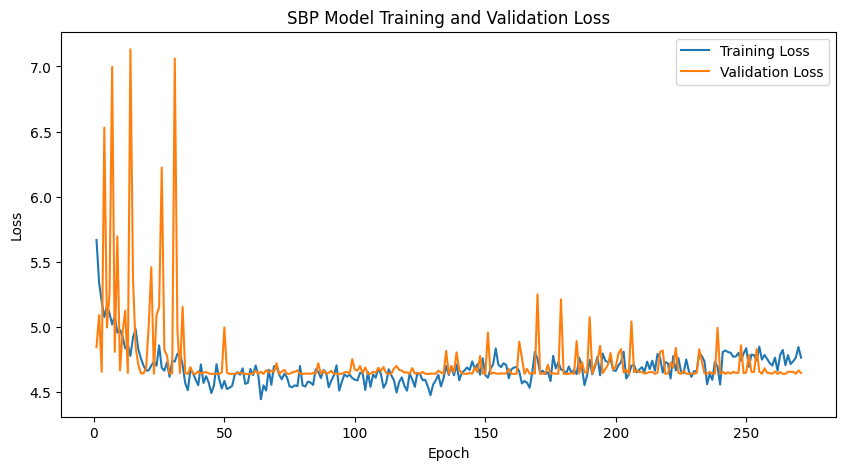

Model Performance Metrics:
MAE: 4.7144
RMSE: 6.1571
Standard Deviation of Errors: 6.1311
R2 Score: -0.0085
BHS Protocol Results:
Within 5 mmHg: 62.35%
Within 10 mmHg: 91.49%
Within 15 mmHg: 96.72%
SBP Model BHS Grade: A
--------------------------------------------------


(4.714427,
 6.157139,
 6.1311107,
 -0.0085085861293972,
 62.3544659250459,
 91.48504158116427,
 96.72102818878928,
 'A')

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epoch+1), train_losses_sbp, label='Training Loss')
plt.plot(range(1, epoch+1), val_losses_sbp, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('SBP Model Training and Validation Loss')
plt.legend()
plt.show()

# Evaluate the model on the test set
predictions_sbp, targets_sbp = evaluate_torch_model(model_sbp, test_loader_sbp, device)
evaluate_model_performance(targets_sbp, predictions_sbp)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model_dbp = BP_Model().to(device)
criterion = nn.L1Loss()
num_epochs = 1000
optimizer = optim.Adam(model_dbp.parameters(), lr=0.01)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.8, patience=patience, verbose=False)
early_stopper = EarlyStopping(patience=patience*3, min_delta=0)

train_losses_dbp, val_losses_dbp, _, _, epoch = train_torch_model(
    model_dbp,
    train_loader_dbp,
    val_loader_dbp,
    num_epochs,
    criterion,
    optimizer,
    device,
    'dbp',
    scheduler,
    early_stopper
)

torch.save(model_dbp.state_dict(), 'model/torch_cnn_lstm_dbp.pth')

Using device: cuda


Epoch 1/1000: 100%|██████████| 1803/1803 [00:41<00:00, 43.78batch/s, loss=4.62, mae=4.62]  


Epoch 1/1000 - Training Loss: 2.3816, MAE: 2.3816, Validation Loss: 2.8423, MAE: 2.8423, Learning Rate: 0.010000


Epoch 2/1000: 100%|██████████| 1803/1803 [00:35<00:00, 50.50batch/s, loss=4.62, mae=4.62]  


Epoch 2/1000 - Training Loss: 2.3427, MAE: 2.3427, Validation Loss: 2.9516, MAE: 2.9516, Learning Rate: 0.010000


...

Epoch 354/1000 - Training Loss: 2.2120, MAE: 2.2120, Validation Loss: 2.3728, MAE: 2.3728, Learning Rate: 0.003277


Epoch 355/1000: 100%|██████████| 1803/1803 [00:35<00:00, 51.03batch/s, loss=4.95, mae=4.95]  


Epoch 355/1000 - Training Loss: 2.2119, MAE: 2.2119, Validation Loss: 2.3715, MAE: 2.3715, Learning Rate: 0.003277


Epoch 356/1000: 100%|██████████| 1803/1803 [00:35<00:00, 51.00batch/s, loss=4.96, mae=4.96]  


Epoch 356/1000 - Training Loss: 2.2120, MAE: 2.2120, Validation Loss: 2.3733, MAE: 2.3733, Learning Rate: 0.003277
Early stopping triggered after 356 epochs.


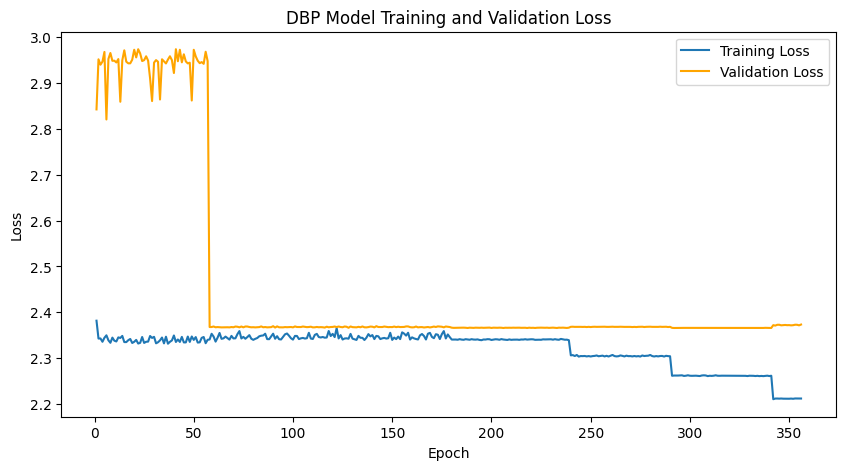

Model Performance Metrics:
MAE: 2.4811
RMSE: 3.0830
Standard Deviation of Errors: 3.0299
R2 Score: -0.0354
BHS Protocol Results:
Within 5 mmHg: 90.42%
Within 10 mmHg: 99.80%
Within 15 mmHg: 99.97%
SBP Model BHS Grade: A
--------------------------------------------------


(2.481126,
 3.0830038,
 3.0298615,
 -0.03538678887258806,
 90.41797170320768,
 99.80127443568419,
 99.96759909277459,
 'A')

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epoch+1), train_losses_dbp, label='Training Loss')
plt.plot(range(1, epoch+1), val_losses_dbp, label='Validation Loss', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DBP Model Training and Validation Loss')
plt.legend()
plt.show()

# Evaluate the model on the test set
predictions_dbp, targets_dbp = evaluate_torch_model(model_dbp, test_loader_dbp, device)
evaluate_model_performance(targets_dbp, predictions_dbp)